In [40]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [41]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import pydicom
print("Toolbox functions ready to define.")

Toolbox functions ready to define.


In [42]:
def _read_dicom(path):
    """Read one DICOM image file; fail clearly if it has no pixel data."""
    ds = pydicom.dcmread(str(path))
    if not hasattr(ds, "PixelData"):
        raise ValueError(f"No image pixel data in {path}")
    return ds

def _pixels(ds):
    """Return rescaled pixel values as floats (not necessarily calibrated HU)."""
    a = np.asarray(ds.pixel_array).astype(float)
    # DICOM can store pixel values with a linear slope/intercept conversion.
    slope = float(getattr(ds, "RescaleSlope", 1))
    intercept = float(getattr(ds, "RescaleIntercept", 0))
    return a * slope + intercept

def load_dicom(path, series_uid=None):
    """Load a DICOM file or a single series from a directory.

    Parameters
    ----------
    path : str or Path
        A single image file or directory containing DICOM files.
    series_uid : str or None
        Select a specific series when the directory contains several.

    Returns
    -------
    image_or_volume : ndarray
        2D for one file; 3D (slice, row, column) for a directory.
    first_dataset : pydicom Dataset
        Header of the first image in the selected series.
    datasets : list
        DICOM datasets in the same order as the returned slices.

    Assumptions: single-frame grayscale images with matching dimensions.
    Check orientation, slice spacing, pixel spacing and units before measuring.
    """
    path = Path(path)
    if path.is_file():
        ds = _read_dicom(path)
        return _pixels(ds), ds, [ds]
    if not path.is_dir():
        raise FileNotFoundError(path)
    groups = {}
    # Scan metadata first so that unrelated series are not mixed together.
    for p in sorted(path.rglob("*")):
        if not p.is_file() or p.name.startswith("."):
            continue
        try:
            h = pydicom.dcmread(str(p), stop_before_pixels=True)
            if not hasattr(h, "Rows"):
                continue
            uid = str(getattr(h, "SeriesInstanceUID", "unknown"))
            groups.setdefault(uid, []).append(p)
        except Exception:
            continue
    if not groups:
        raise ValueError("No readable DICOM image files found")
    print("Available series:")
    for uid, paths in groups.items():
        print(f"  {uid} : {len(paths)} files")
    if series_uid is None and len(groups) > 1:
        raise ValueError("Multiple series: set SERIES_UID to one listed above")
    uid = series_uid or next(iter(groups))
    if uid not in groups:
        raise ValueError("SERIES_UID not found")
    dsets = [_read_dicom(p) for p in groups[uid]]
    def sort_key(ds):
        """Sort slices by physical position if available; otherwise instance number."""
        try:
            orient = np.asarray(ds.ImageOrientationPatient, float)
            normal = np.cross(orient[:3], orient[3:])
            return float(np.dot(np.asarray(ds.ImagePositionPatient, float), normal))
        except Exception:
            return float(getattr(ds, "InstanceNumber", 0))
    dsets.sort(key=sort_key)
    arrs = [_pixels(ds) for ds in dsets]
    if len({a.shape for a in arrs}) != 1:
        raise ValueError("Different image shapes within series")
    return np.stack(arrs, axis=0), dsets[0], dsets

def pixel_spacing_mm(ds):
    """Return (row_spacing, column_spacing) in mm/pixel, or None if absent."""
    if hasattr(ds, "PixelSpacing"):
        return tuple(float(v) for v in ds.PixelSpacing)
    return None

def show_metadata(ds, arr):
    """Print image dimensions and metadata needed to judge measurement validity."""
    print("Array shape:", arr.shape)
    for field in ["Modality", "SeriesDescription", "PixelSpacing", "SliceThickness", "SpacingBetweenSlices", "PhotometricInterpretation", "RescaleSlope", "RescaleIntercept"]:
        print(f"{field}: {getattr(ds, field, 'not provided')}")
    print("WARNING: confirm image geometry, pixel calibration, and orientation before physical measurements.")

# PixelSpacing is (row, column) mm/pixel, NOT (x, y).
# Slice thickness is not necessarily the distance between adjacent slice centres.
# Do not combine different series without checking geometry and scaling.
# This basic loader is not designed for colour ultrasound or multiframe data.

In [43]:
def make_demo():
    """Create a synthetic 2D image with simple structures and added variation.

    This image is ONLY for learning the functions. Intensities and spacing
    are arbitrary; they are not CT HU or measurements of a real phantom.
    """
    yy, xx = np.mgrid[:160, :200]
    img = np.full((160, 200), 18.0)
    # Add structures of different shapes/intensities to test analysis choices.
    img[((xx-62)/25)**2 + ((yy-80)/38)**2 < 1] = 65
    img[((xx-62)/10)**2 + ((yy-80)/14)**2 < 1] = 125
    img[((xx-140)/24)**2 + ((yy-83)/27)**2 < 1] = 42
    rng = np.random.default_rng(22481)
    return img + rng.normal(0, 3, img.shape)

In [ ]:
def show_image(img, spacing=None, vmin=None, vmax=None, title="Image"):
    """Display a 2D image with optional physical axes.

    spacing : (row_mm, column_mm) or None
        If omitted, axes show pixels. If supplied, axes show mm.
    vmin, vmax : optional display limits
        Change image appearance only; do not change underlying pixel values.
    Returns (figure, axes) for further annotations or saving.
    """
    fig, ax = plt.subplots(figsize=(7, 9))
    if spacing is None:
        ax.imshow(img, cmap="gray", origin="upper", vmin=vmin, vmax=vmax)
        ax.set(xlabel="Column (pixels)", ylabel="Row (pixels)")
    else:
        dy, dx = spacing  # DICOM stores row spacing before column spacing.
        ax.imshow(img, cmap="gray", origin="upper", vmin=vmin, vmax=vmax,
                  extent=[0, img.shape[1]*dx, img.shape[0]*dy, 0])
        ax.set(xlabel="Horizontal distance (mm)", ylabel="Vertical distance (mm)")
    ax.set_title(title)
    return fig, ax

In [45]:
def distance_mm(p1_xy, p2_xy, spacing):
    """Distance in mm between two pixel positions (x=column, y=row).

    spacing must be verified (row_mm, column_mm). Suitable for a 2D
    image with orthogonal in-plane pixel axes; not a 3D distance.
    """
    if spacing is None:
        raise ValueError("Physical pixel spacing not verified")
    dy, dx = spacing
    # Convert horizontal and vertical pixel differences separately to mm.
    return float(np.hypot((p2_xy[0]-p1_xy[0])*dx, (p2_xy[1]-p1_xy[1])*dy))

def line_profile(img, p1_xy, p2_xy, spacing=None, samples=300):
    """Sample intensities along a line between two (column, row) positions.

    Returns (distance_along_line, intensity_values, distance_unit).
    Uses nearest-neighbour sampling: repeated pixels and stair-step edges
    are possible. Choose endpoints based on your scientific question.
    """
    x = np.linspace(p1_xy[0], p2_xy[0], samples)
    y = np.linspace(p1_xy[1], p2_xy[1], samples)
    # Round sampling locations to nearest existing pixels (no interpolation).
    xi = np.clip(np.rint(x).astype(int), 0, img.shape[1]-1)
    yi = np.clip(np.rint(y).astype(int), 0, img.shape[0]-1)
    values = img[yi, xi]
    if spacing is None:
        dist = np.linspace(0, np.hypot(x[-1]-x[0], y[-1]-y[0]), samples)
        unit = "pixels"
    else:
        dist = np.linspace(0, distance_mm(p1_xy, p2_xy, spacing), samples)
        unit = "mm"
    return dist, values, unit

In [53]:
def ultrasound_analysis(filename, P1=None, P2=None, W=234, L=127, measurement=True):

    # Load ultrasound image
    volume, ds, slices = load_dicom(filename)
    image = volume

    # Window and Level
    vmin = L - W/2
    vmax = L + W/2

    # -----------------------------------
    # Display image
    # -----------------------------------

    fig, ax = show_image(
        image,
        vmin=vmin,
        vmax=vmax,
        title="Ultrasound"
    )

    # Window/Level on image
    ax.text(
        0.02, 0.98,
        f"Window/Level: {W}/{L}",
        transform=ax.transAxes,
        color="white",
        fontsize=15,
        va="top",
        bbox=dict(facecolor="black", alpha=0.7)
    )

    length = None

    # -----------------------------------
    # Optional measurement
    # -----------------------------------

    if measurement:

        if P1 is None or P2 is None:
            raise ValueError("You must provide P1 and P2 when measurement=True")

        # Physical distance
        region = ds.SequenceOfUltrasoundRegions[0]

        dx = abs(float(region.PhysicalDeltaX)) * 10
        dy = abs(float(region.PhysicalDeltaY)) * 10

        spacing = (dy, dx)

        # Teacher's distance function
        length = distance_mm(P1, P2, spacing)

        # Yellow measurement line
        ax.plot(
            [P1[0], P2[0]],
            [P1[1], P2[1]],
            color="yellow",
            linewidth=2,
            marker="o"
        )

        # Length on image
        ax.text(
            150,
            750,
            f"{length:.2f} mm",
            color="yellow",
            fontsize=12,
            fontweight="bold",
            ha="center",
            bbox=dict(facecolor="black", alpha=0.7)
        )

    # -----------------------------------
    # Axis formatting
    # -----------------------------------

    ax.set_xlabel("Column (pixels)", fontsize=16, fontweight="bold")
    ax.set_ylabel("Row (pixels)", fontsize=16, fontweight="bold")

    ax.tick_params(axis="both", labelsize=14)

    ax.set_title("Ultrasound", fontsize=18, fontweight="bold")

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

    plt.tight_layout()
    plt.show()

    if measurement:
        print(f"Length: {length:.2f} mm")

    return length

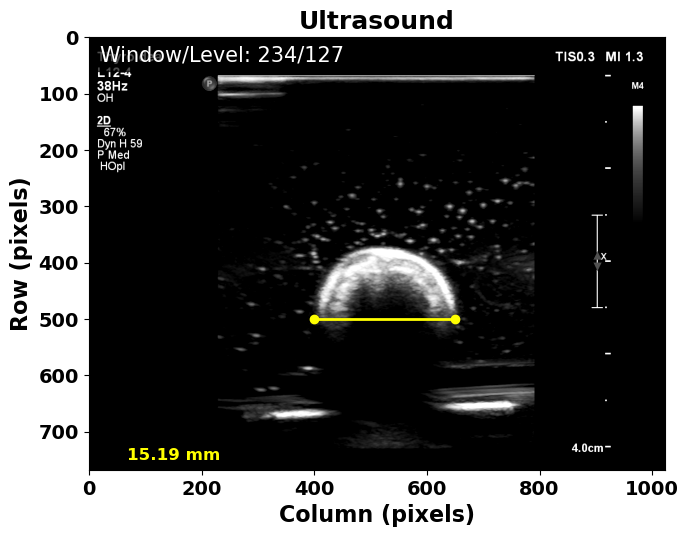

Length: 15.19 mm


15.193079409094016

In [54]:
ultrasound_analysis(
    filename="6B_01.dcm",
    P1=(400, 500),
    P2=(650, 500),
    W=234,
    L=127,
    measurement=True
)

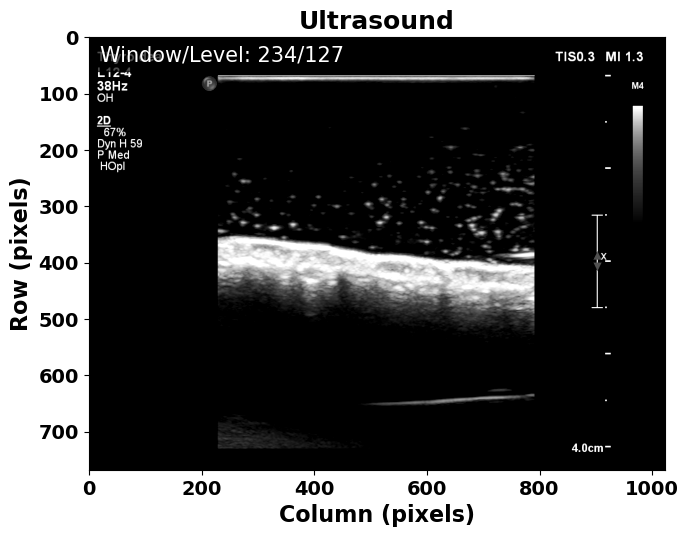

In [ ]:
ultrasound_analysis(
    filename="6B_02.dcm",
    P1=(400, 500),
    P2=(650, 500),
    W=234,
    L=127,
    measurement=False
)

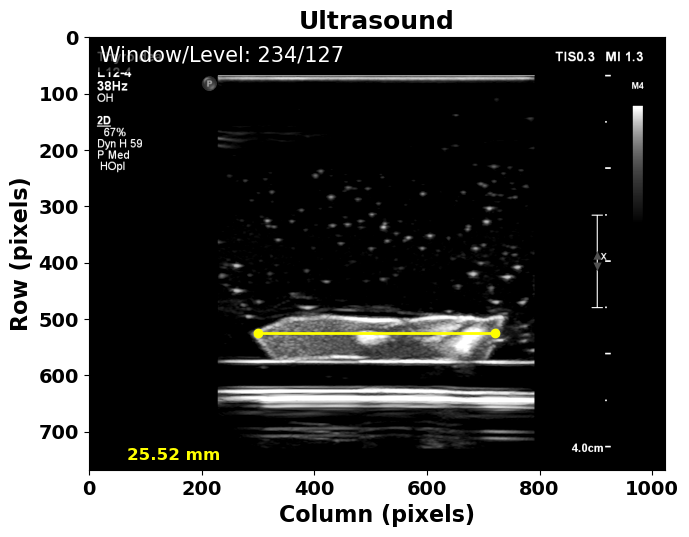

Length: 25.52 mm


25.52437340727795

In [61]:
ultrasound_analysis(
    filename="6B_03.dcm",
    P1=(300, 525),
    P2=(720, 525),
    W=234,
    L=127,
    measurement=True
)

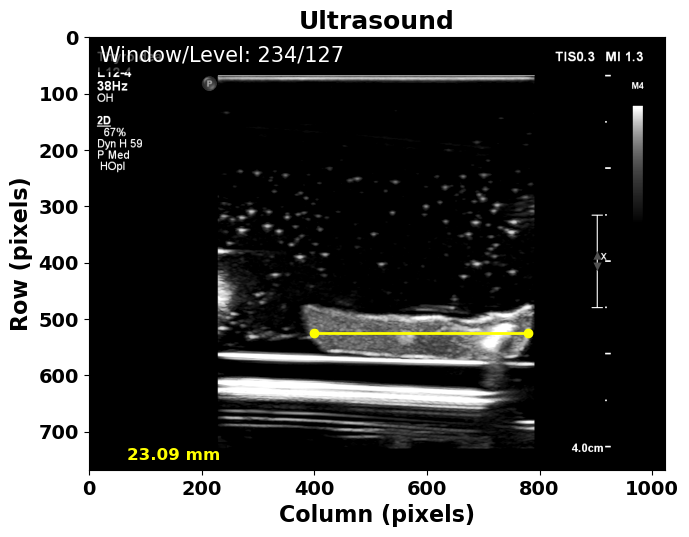

Length: 23.09 mm


23.093480701822905

In [66]:
ultrasound_analysis(
    filename="6B_04.dcm",
    P1=(400, 525),
    P2=(780, 525),
    W=234,
    L=127,
    measurement=True
)

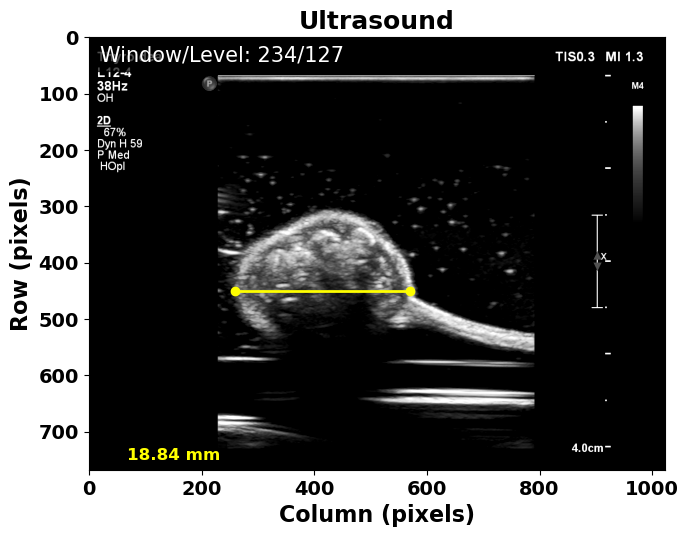

Length: 18.84 mm


18.83941846727658

In [71]:
ultrasound_analysis(
    filename="6B_05.dcm",
    P1=(260, 450),
    P2=(570, 450),
    W=234,
    L=127,
    measurement=True
)

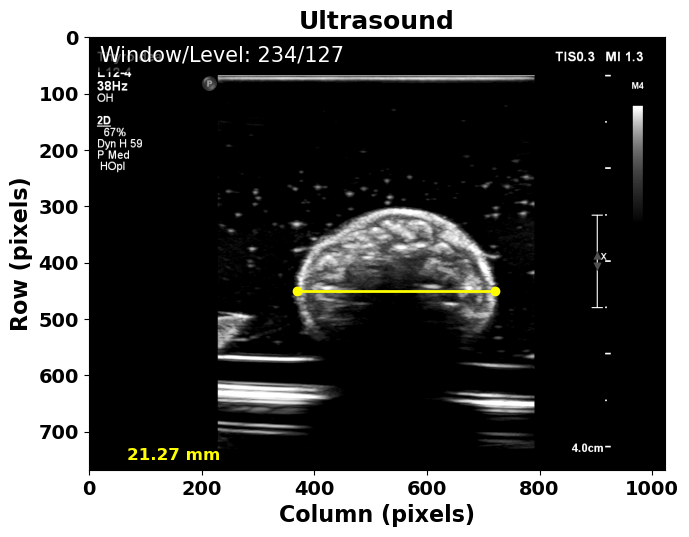

Length: 21.27 mm


21.270311172731624

In [76]:
ultrasound_analysis(
    filename="6B_06.dcm",
    P1=(370, 450),
    P2=(720, 450),
    W=234,
    L=127,
    measurement=True
)